# 028 — Ensemble com características por domínio

Comparação emparelhada: XGBoost (200 árvores, depth=5, lr=0,1) + MLP 64→32 (ReLU, dropout=0,1, Adam lr=0,0001, batch=128, perda com pesos 1/√frequência), probabilidades 75/25. Máximo 100 épocas; a época de cada versão é selecionada pela Macro F1 do MLP na validação interna. A preferência entre versões usa a Macro F1 interna do ensemble.

O 025 teve Macro F1 histórica 0,4615 e Kaggle **0,48**. Os módulos originais dos controlos não foram fornecidos; o controlo é reconstruído e usa a preparação central disponível. Não se afirma reprodução exata das métricas históricas. A comparação atual com/sem agregados é emparelhada.

Treino/validação fixa: 80/20 estratificado, seed 42; validação interna: 15% do treino, seed 42. A validação fixa já foi consultada e serve para desenvolvimento. Nenhum resultado do Kaggle seleciona modelos.


In [1]:
from pathlib import Path
import sys, json
from IPython.display import display, Image, Markdown
import pandas as pd

root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'src' / 'experiments_028_029.py').is_file() and (p / 'src' / 'preparar_dados.py').is_file()), None)
if root is None:
    raise FileNotFoundError('Coloca os dois módulos fornecidos em src/ e este notebook em notebooks/. Mantém src/preparar_dados.py do projeto.')
sys.path.insert(0, str(root))
from src.experiments_028_029 import run_experiment, load_data, write_final_report
print('Projeto:', root)
print('Python:', sys.version.split()[0])


Projeto: /workspace/scratch/4c152c3aae12
Python: 3.12.14


## Preparação e garantias

O módulo central `src/preparar_dados.py` faz a preparação fixa. No 028, o seu `DataPreprocessor` é ajustado por partição; os novos agregados recebem um ramo numérico adicional (mediana e normalização no MLP), sem modificar o comportamento de notebooks anteriores. No 029, números ausentes são tratados nativamente pelo CatBoost; categorias ausentes recebem um rótulo explícito. O esquema é consistente e códigos categóricos não são convertidos para quantidades por terem algarismos.

`AGE_RANGE`, `PID`, `HHID`, `PROXY` e `COUNTRY` ficam fora das entradas. BM1/BM2 e BMI/IMC são numéricos; cm/kg continuam uma suposição por confirmar. Os índices e a ordem são preservados. Não se eliminam linhas.

Os runners guardam resultados e o CatBoost guarda checkpoints por candidato. Para reutilizar resultados existentes, a célula seguinte verifica os hashes dos CSVs e da preparação. Define `REEXECUTAR=True` para executar novamente. Em caso de código/configuração alterados, reexecuta deliberadamente e apaga apenas os checkpoints correspondentes antes de retomar.


## Agregados opcionais: significado e fórmulas

Base semântica: enunciado fornecido pelo grupo, e não um dicionário integral do questionário. CD1A–CD1P são indicadores de condições crónicas; PC1A–PC1E referem autocuidado; HA1A–HA1G tarefas domésticas/administrativas. PL6–PL8 formam um resumo operacional de **itens funcionais**, sem atribuir tarefas motoras específicas. PL1/PL3 (Sim/Não sobre utilização de ajudas) e PL9_tot (possível total) ficam excluídos.

- CD1: positivo=`Sim`; negativo=`Não`.
- PL6–PL8, PC1 e HA1: positivo=`Alguma dificuldade`, `Muita dificuldade` ou `Não consegue de todo`; negativo=`Nenhuma dificuldade`.
- Para cada grupo: `validas`=positivos+negativos; `positivas`=número de respostas positivas; `proporcao`=positivas/válidas.
- `Sem resposta`, `Não aplicável` (incluindo nunca tentou/não precisa), `Não sabe` e ausência não contam como negativas nem entram no denominador. Com zero válidas, contagem positiva e proporção ficam NaN; válidas fica zero.
- Mantêm-se todos os itens originais. Os resumos não são escalas clínicas, contagens de diagnósticos distintos ou avaliações de envelhecimento biológico. Os diferentes universos de aplicação podem influenciar os resumos e exigem interpretação cautelosa.

A função em `src/caracteristicas_dominio.py` está desativada por defeito. A preparação é determinística por linha. A lista dos grupos e as fórmulas ficam explícitas no código, sem seleção aprendida no conjunto completo.


In [2]:
REEXECUTAR = False
path = root / 'reports' / '028_resultado.json'
_, _, _, _, metadata = load_data()
if path.exists() and not REEXECUTAR:
    result = json.loads(path.read_text())
    if any(result['metadata'][k] != metadata[k] for k in ['train_sha256','test_sha256','preparation_sha256']):
        raise ValueError('Os dados ou a preparação mudaram. Reexecuta a experiência; não uses métricas antigas.')
    print('Resultados executados anteriormente, dados/preparação conferidos.')
else:
    result = run_experiment('028')


Resultados executados anteriormente, dados/preparação conferidos.


## Resultados e curvas

controlo — validação fixa
agregados — validação fixa


,versão,parcela,época,Macro F1 interna ensemble,Macro F1,accuracy
0,controlo,train,99,0.461771,0.949045,0.938305
1,controlo,validation,99,0.461771,0.458528,0.462380
2,agregados,train,96,0.474464,0.950410,0.940016
3,agregados,validation,96,0.474464,0.463376,0.464660


,classe,escalão,F1,recall,precision,support
0,0,15–17,0.809524,0.829268,0.790698,41.000000
1,1,18–19,0.415094,0.323529,0.578947,34.000000
2,2,20–24,0.614458,0.637500,0.593023,80.000000
3,3,25–29,0.319444,0.306667,0.333333,75.000000
4,4,30–34,0.243590,0.211111,0.287879,90.000000
5,5,35–39,0.362369,0.403101,0.329114,129.000000
6,6,40–44,0.353293,0.343023,0.364198,172.000000
7,7,45–49,0.400000,0.398844,0.401163,173.000000
8,8,50–54,0.619423,0.651934,0.590000,181.000000
9,9,55–59,0.619512,0.625616,0.613527,203.000000


,classe,escalão,F1,recall,precision,support
0,0,15–17,0.837209,0.878049,0.800000,41.000000
1,1,18–19,0.448276,0.382353,0.541667,34.000000
2,2,20–24,0.616352,0.612500,0.620253,80.000000
3,3,25–29,0.347222,0.333333,0.362319,75.000000
4,4,30–34,0.259740,0.222222,0.312500,90.000000
5,5,35–39,0.321168,0.341085,0.303448,129.000000
6,6,40–44,0.361582,0.372093,0.351648,172.000000
7,7,45–49,0.423188,0.421965,0.424419,173.000000
8,8,50–54,0.622340,0.646409,0.600000,181.000000
9,9,55–59,0.622871,0.630542,0.615385,203.000000


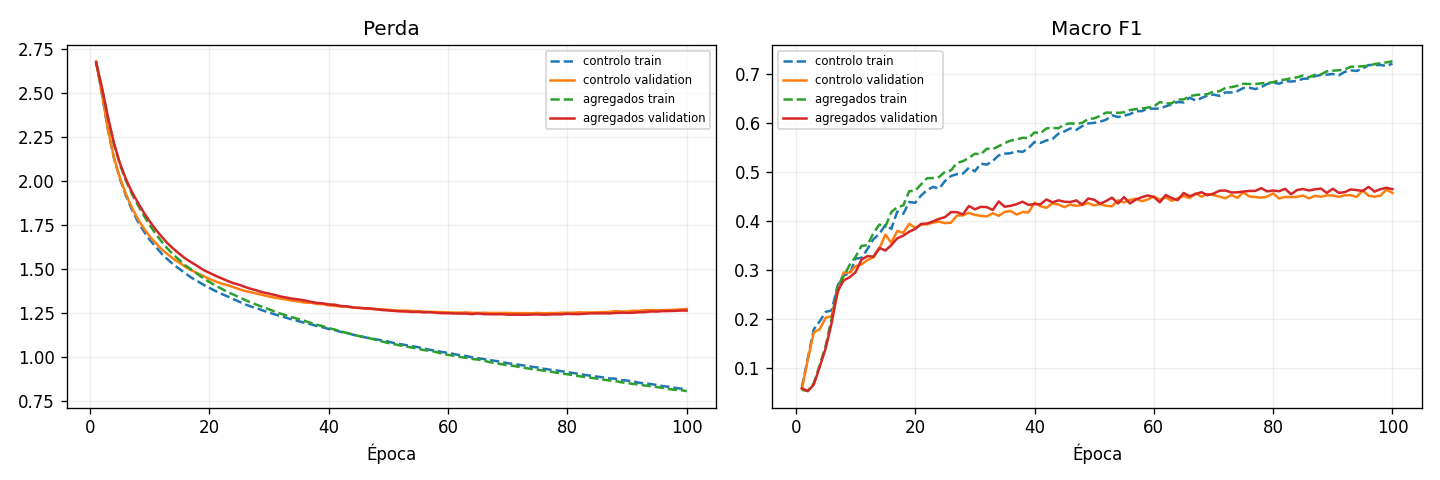

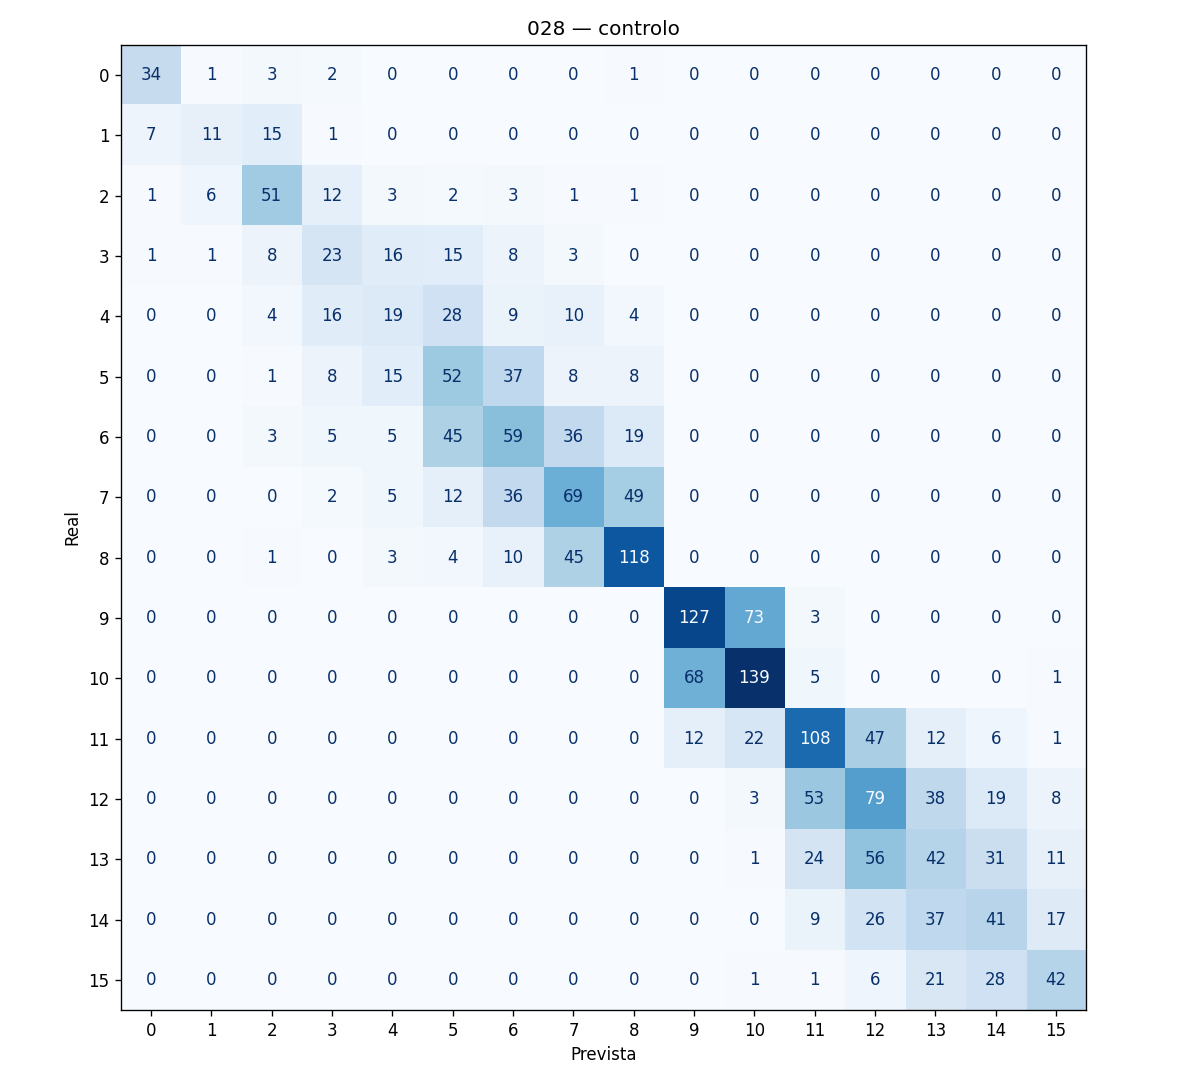

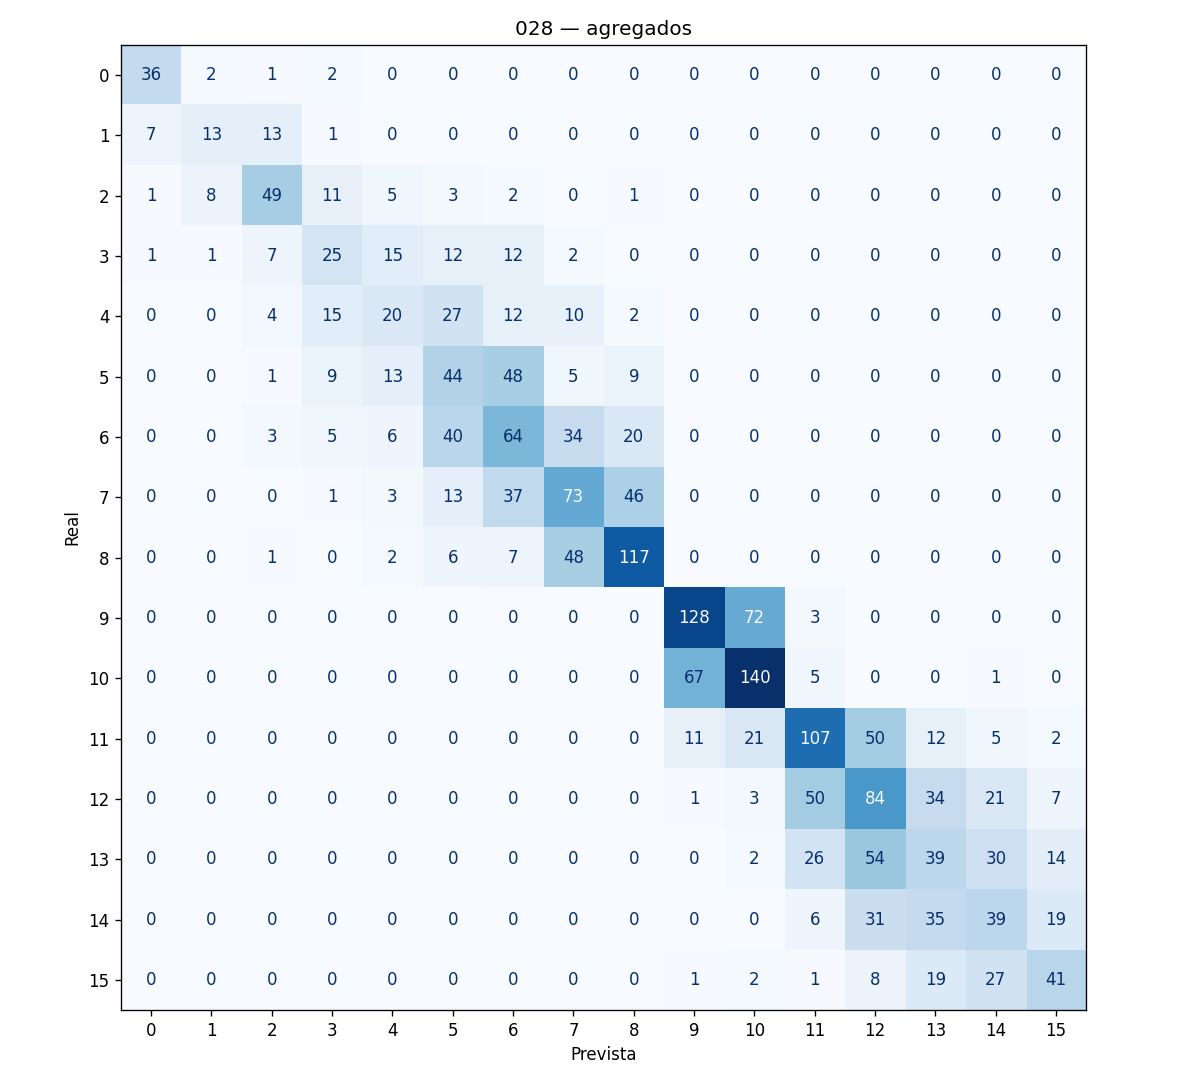

In [3]:
summary=[]
for name, r in result['variants'].items():
    for split in ['train','validation']:
        summary.append({'versão':name,'parcela':split,'época':r['epoch'],'Macro F1 interna ensemble':r['internal_ensemble_macro_f1'],'Macro F1':r[split]['macro_f1'],'accuracy':r[split]['accuracy']})
display(pd.DataFrame(summary))
for name,r in result['variants'].items():
    print(name, '— validação fixa')
    display(pd.DataFrame(r['validation']['per_class']).style.apply(lambda row:['font-weight:bold' if row['classe'] in [1,6,13] else '' for _ in row],axis=1))
display(Image(filename=str(root/'reports/028_curvas.png')))
for name in result['variants']:
    display(Image(filename=str(root/f'reports/028_{name}_confusion.png')))


## Submissão e verificações

Treino completo com configuração escolhida internamente. CSV relido e validado: 3.655 linhas, `RowId,AGE_RANGE`, RowIds copiados do exemplo oficial, classes inteiras 0–15 e sem índice. Duplicados são detetados entre os ficheiros anteriores disponíveis; a ausência de CSVs 016/019/025 impede comparar com esses ficheiros específicos aqui. Não foi submetido nada ao Kaggle.

In [5]:
print(json.dumps(result['submission'],ensure_ascii=False,indent=2))
print(write_final_report())

{
  "path": "submissions/submission_028_ensemble_features_dominio.csv",
  "duplicates": [],
  "differences": {
    "submission_013_mlp_arquitetura.csv": 1435,
    "submission_014_xgboost_mlp.csv": 560,
    "submission_001_regressao_logistica(1).csv": 1428,
    "submission_012_mlp_perda_ponderada.csv": 1435,
    "submission_004_arvore_decisao.csv": 2097,
    "submission_015_mlp_learning_rate.csv": 1300,
    "submission_002_regressao_logistica_regularizada.csv": 1179
  }
}
/workspace/scratch/4c152c3aae12/reports/experiments_028_029.md


## Conclusão e Decisão 
- Data: 13/11
- Pontuação Kaggle: 0.47
- Conclusão: Os agregados melhoraram a validação local, mas esse ganho não se confirmou no Kaggle.
- Melhorias: testar cada grupo de agregados separadamente e verificar a estabilidade em validação cruzada, mantendo os mesmos folds para o controlo.